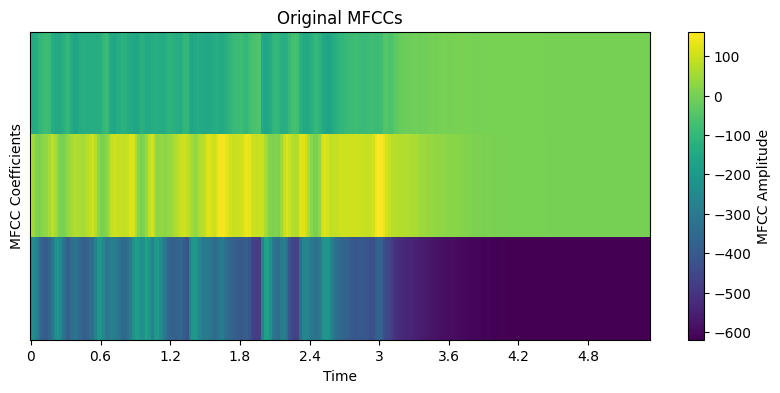

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import sklearn

# Load an example speech-like audio file (change this to a real speech file if available)
y, sr = librosa.load(librosa.example('trumpet'), sr=None)  # Replace with actual speech audio

# Compute MFCCs (Mel-Frequency Cepstral Coefficients)
n_mfcc = 3  # Number of MFCC features
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

# Display the original MFCCs
plt.figure(figsize=(10, 4))
librosa.display.specshow(mfccs, x_axis='time', sr=sr, cmap='viridis')
plt.colorbar(label='MFCC Amplitude')
plt.title('Original MFCCs')
plt.xlabel('Time')
plt.ylabel('MFCC Coefficients')
plt.show()



In [20]:
def pca(X, num_components=None):
    # 1. Center the data
    X_mean = np.mean(X, axis=0)
    X_centered = X - X_mean
    
    # 2. Compute the covariance matrix
    covariance_matrix = np.cov(X_centered, rowvar=False)
    
    # 3. Compute eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
    
    # 4. Sort eigenvalues and eigenvectors in descending order
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    
    # 5. Select the top 'num_components' principal components
    if num_components is not None:
        eigenvectors = eigenvectors[:, :num_components]
        eigenvalues = eigenvalues[:num_components]
    
    # Project the data onto the principal components
    X_pca = np.dot(X_centered, eigenvectors)
    
    return X_pca, eigenvectors, eigenvalues


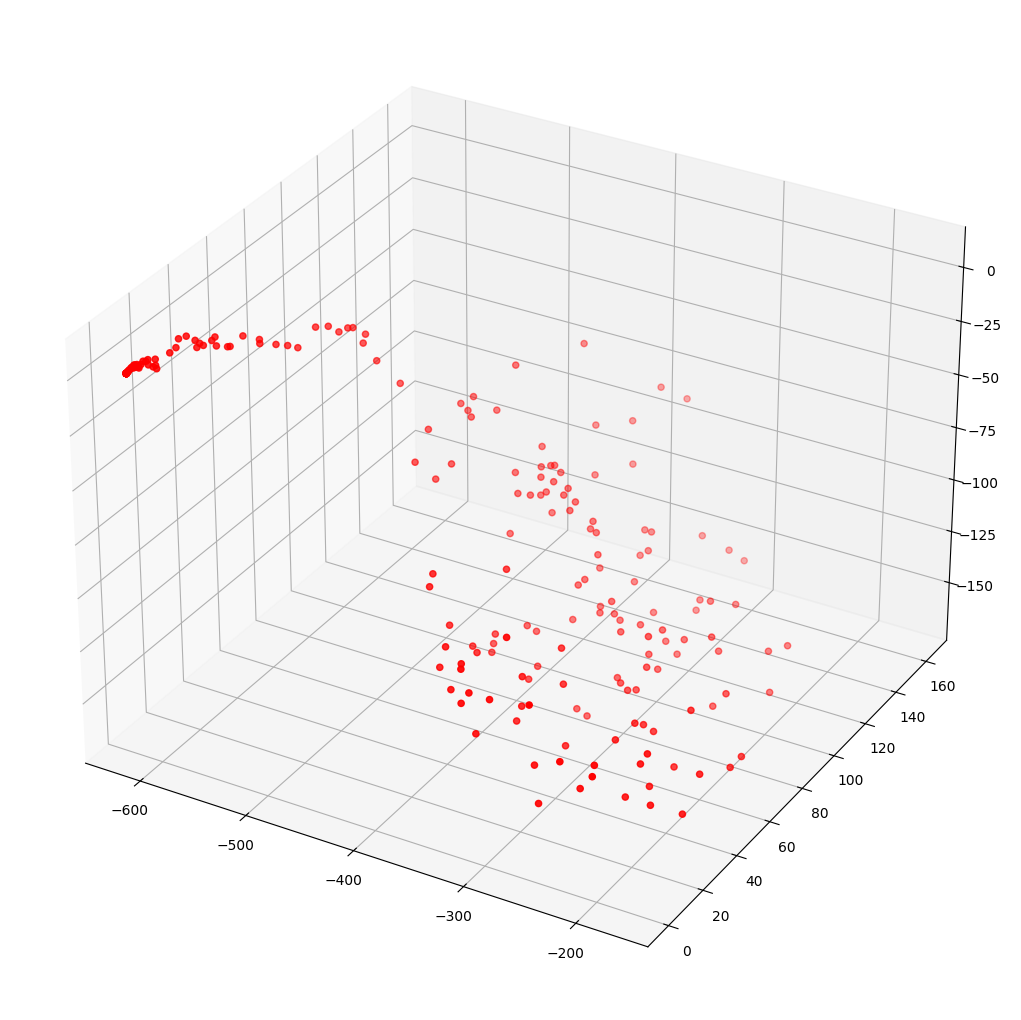

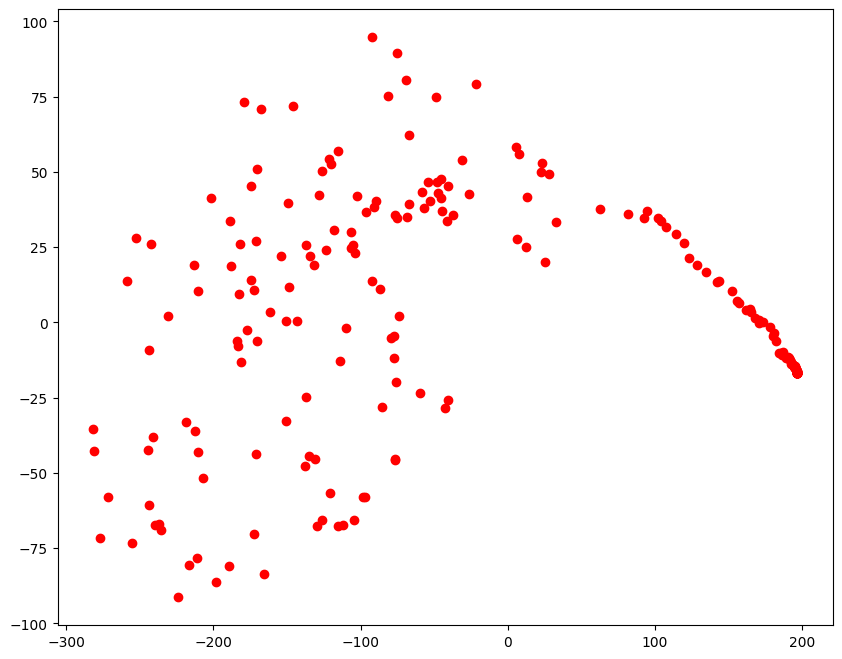

In [23]:
fig = plt.figure(figsize=(20,13))
ax = fig.add_subplot(1,1,1, projection='3d')
ax.scatter(mfccs[0,:], mfccs[1,:], mfccs[2,:], c='r', marker='o')
plt.show()

#Apply the tranformation
X_pca,_,_ = pca(mfccs.T,2)
fig = plt.figure(figsize=(10,8))
plt.scatter(X_pca[:,0], X_pca[:,1], c='r', marker='o')
plt.show()